<a href="https://colab.research.google.com/github/Geranxyz/edu_task/blob/main/UTS_MachiceLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Pengelompokan Pola Harga Komoditas Pangan di Berbagai Pasar Indonesia Menggunakan Algoritma K-Means

---

## 1. Business Understanding

### Latar Belakang Permasalahan
Komoditas pangan pokok seperti beras, bawang merah, bawang putih, cabai merah, dan daging merupakan kebutuhan dasar masyarakat Indonesia yang harganya sangat fluktuatif. Fluktuasi harga ini dipengaruhi oleh berbagai faktor seperti rantai pasok, musim panen, cuaca ekstrem, serta perbedaan kondisi geografis dan infrastruktur antarwilayah di Indonesia. Ketidakstabilan harga pangan berisiko memicu inflasi serta mengganggu ketahanan pangan masyarakat. Oleh karena itu, diperlukan sebuah pendekatan berbasis data untuk mengelompokkan pola harga komoditas pangan agar pemerintah dan pelaku industri dapat melakukan intervensi pasar yang lebih tepat sasaran.

### Rumusan Masalah
1. Bagaimana mengelompokkan pola harga berbagai komoditas pangan di pasar Indonesia untuk melihat karakteristik wilayah/periode tertentu?
2. Berapa jumlah cluster optimal yang dapat merepresentasikan pola harga komoditas pangan ini?
3. Bagaimana dampak proses standardisasi (*feature scaling*) terhadap kualitas pengelompokan menggunakan algoritma K-Means?

### Tujuan Penelitian
1. Mengidentifikasi pengelompokan pola harga komoditas pangan di Indonesia menggunakan algoritma K-Means.
2. Menentukan jumlah cluster terbaik melalui Elbow Method dan Silhouette Score.
3. Membandingkan performa dan interpretasi hasil clustering antara data sebelum (*raw data*) dan sesudah standardisasi (*scaled data*).

### Manfaat Penelitian
- **Bagi Akademisi/Mahasiswa**: Memberikan pemahaman praktis mengenai penerapan metodologi CRISP-DM dan algoritma K-Means pada data riil sektoral di Indonesia.
- **Bagi Pemerintah/Pengambil Kebijakan**: Membantu memetakan wilayah atau periode dengan tingkat harga pangan tertentu (misal: klaster harga tinggi, sedang, rendah) guna merumuskan kebijakan stabilisasi harga.

### Pengguna Hasil Analisis
- Dinas Perdagangan dan Ketahanan Pangan.
- Satgas Pangan.
- Analis Kebijakan Ekonomi Makro.
- Pelaku usaha logistik pangan.

### Keputusan Saya (Business Understanding)
**Keputusan:** Fokus analisis akan diarahkan pada pengelompokan harga rata-rata berbagai komoditas pangan utama (Beras, Bawang Merah, Bawang Putih, Cabai Merah) untuk mengidentifikasi pola pasar.
**Alasan:** Menggunakan multikomoditas memungkinkan pemenuhan syarat minimal 3 fitur numerik serta memberikan gambaran komprehensif mengenai keranjang belanja pangan pokok masyarakat.

## 2. Data Understanding

Pada tahap ini, kita akan mengimpor library yang diperlukan, membaca beberapa file dataset komoditas pangan yang tersedia di direktori lokal, menggabungkannya ke dalam satu DataFrame terpadu, dan melakukan analisis statistik deskriptif awal.

In [23]:
# 2.1 Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import os

# Mengatur visualisasi agar terlihat rapi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 2.2 Menentukan SEED berdasarkan 3 digit terakhir NIM (Misal NIM belakang: 123)
# Silakan sesuaikan SEED ini dengan 3 digit terakhir NIM Anda!
SEED = 123
print(f"Random State / SEED yang digunakan: {SEED}")

Random State / SEED yang digunakan: 123


In [24]:
# 2.3 Membaca dan Menggabungkan Dataset Komoditas
# Kita akan membaca beberapa komoditas dan menggabungkannya berdasarkan kolom tanggal agar membentuk dataset multidimensi

file_paths = {
    'beras': '/content/final_komoditas_modern_beras_2022_2026.csv',
    'bawang_merah': '/content/final_komoditas_modern_bawang_merah_2022_2026.csv',
    'bawang_putih': '/content/final_komoditas_modern_bawang_putih_2022_2026.csv',
    'cabai_merah': '/content/final_komoditas_modern_cabai_merah_2022_2026.csv'
}

dfs = {}
for komoditas, path in file_paths.items():
    if os.path.exists(path):
        # Membaca dataset
        temp_df = pd.read_csv(path)
        # Memastikan nama kolom seragam (misal: 'Tanggal' dan 'Harga' / 'Nasional')
        # Kita asumsikan dataset memiliki kolom Tanggal dan kolom Harga (Nasional atau rata-rata)
        # Mari kita tampilkan info kolom pertama untuk memastikan strukturnya
        print(f"Struktur Kolom {komoditas.upper()}:")
        print(temp_df.columns.tolist()[:5])
        dfs[komoditas] = temp_df
    else:
        print(f"File untuk {komoditas} tidak ditemukan di {path}")

Struktur Kolom BERAS:
['Date_Param', 'Aceh', 'Bali', 'Banten', 'Bengkulu']
Struktur Kolom BAWANG_MERAH:
['Date_Param', 'Aceh', 'Bali', 'Banten', 'Bengkulu']
Struktur Kolom BAWANG_PUTIH:
['Date_Param', 'Aceh', 'Bali', 'Banten', 'Bengkulu']
Struktur Kolom CABAI_MERAH:
['Date_Param', 'Aceh', 'Bali', 'Banten', 'Bengkulu']


In [25]:
# Mari kita gabungkan data harga komoditas nasional tersebut berdasarkan Tanggal.
# Biasanya dataset ini memiliki struktur kolom: Tanggal, dan wilayah-wilayah.
# Kita akan mengambil kolom 'Tanggal' dan harga 'Pusat' atau rata-rata nasional untuk disatukan.

# Mari kita periksa isi salah satu dataframe secara detail
sample_key = list(dfs.keys())[0]
display(dfs[sample_key].head())

,Date_Param,Aceh,Bali,Banten,Bengkulu,DI Yogyakarta,DKI Jakarta,Gorontalo,Jambi,Jawa Barat,...,Papua Barat,Riau,Sulawesi Barat,Sulawesi Selatan,Sulawesi Tengah,Sulawesi Tenggara,Sulawesi Utara,Sumatera Barat,Sumatera Selatan,Sumatera Utara
0,2022-01-01,12500.0,11850.0,16800.0,12850.0,14500.0,12800.0,13900.0,11850.0,12850.0,...,13150.0,12200.0,10450.0,16250.0,13100.0,18600.0,12400.0,15150.0,13050.0,12800.0
1,2022-01-02,12500.0,11850.0,16800.0,12850.0,14500.0,12800.0,13900.0,11850.0,12850.0,...,13150.0,12200.0,10450.0,16250.0,13100.0,18600.0,12400.0,15150.0,13050.0,12800.0
2,2022-01-03,12500.0,11800.0,16800.0,12850.0,14500.0,12800.0,13900.0,11850.0,12850.0,...,13150.0,12200.0,10450.0,16250.0,13100.0,18600.0,12400.0,15150.0,13050.0,12800.0
3,2022-01-04,12500.0,11850.0,16800.0,12850.0,14500.0,12950.0,13900.0,11850.0,12850.0,...,13150.0,12200.0,10450.0,16250.0,13100.0,18600.0,12400.0,15150.0,13050.0,12800.0
4,2022-01-05,12500.0,11850.0,16800.0,12850.0,14500.0,12950.0,13900.0,11850.0,12850.0,...,13250.0,12200.0,10450.0,16250.0,13100.0,18600.0,12400.0,15150.0,12900.0,12750.0


In [26]:
# Kita akan menyusun dataset multikomoditas menggunakan data harga wilayah tertentu (misal: 'Aceh')
# Kita menggunakan 'Date_Param' sebagai key penghubung karena kolom tersebut merupakan kolom tanggal di dataset

combined_df = None

for komoditas, df_kom in dfs.items():
    # Bersihkan nama kolom jika ada spasi
    df_kom.columns = df_kom.columns.str.strip()

    # Kita pilih kolom 'Aceh' sebagai fitur numerik yang konsisten ada di semua file
    target_col = 'Aceh'

    if target_col in df_kom.columns and 'Date_Param' in df_kom.columns:
        sub_df = df_kom[['Date_Param', target_col]].rename(columns={target_col: f'Harga_{komoditas}'})

        # Konversi tipe data harga ke numerik jika bertipe object/string
        if sub_df[f'Harga_{komoditas}'].dtype == 'object':
            sub_df[f'Harga_{komoditas}'] = sub_df[f'Harga_{komoditas}'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)

        if combined_df is None:
            combined_df = sub_df
        else:
            combined_df = pd.merge(combined_df, sub_df, on='Date_Param', how='inner')

# Menampilkan 5 data pertama hasil penggabungan
print("Hasil Penggabungan Dataset Komoditas Pangan:")
display(combined_df.head())
print(f"Dimensi Dataset: {combined_df.shape[0]} baris dan {combined_df.shape[1]} kolom")

Hasil Penggabungan Dataset Komoditas Pangan:


,Date_Param,Harga_beras,Harga_bawang_merah,Harga_bawang_putih,Harga_cabai_merah
0,2022-01-01,12500.0,47500.0,42000.0,37000.0
1,2022-01-02,12500.0,47500.0,42000.0,37000.0
2,2022-01-03,12500.0,47500.0,42000.0,37000.0
3,2022-01-04,12500.0,47500.0,42000.0,37000.0
4,2022-01-05,12500.0,39900.0,38500.0,37500.0


Dimensi Dataset: 1493 baris dan 5 kolom


In [27]:
# 2.4 Menampilkan tipe data dan deskripsi statistik setiap kolom
print("--- Tipe Data Kolom ---")
print(combined_df.info())

print("\n--- Statistik Deskriptif ---")
display(combined_df.describe())

--- Tipe Data Kolom ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1493 entries, 0 to 1492
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date_Param          1493 non-null   object 
 1   Harga_beras         1493 non-null   float64
 2   Harga_bawang_merah  1493 non-null   float64
 3   Harga_bawang_putih  1493 non-null   float64
 4   Harga_cabai_merah   1493 non-null   float64
dtypes: float64(4), object(1)
memory usage: 58.4+ KB
None

--- Statistik Deskriptif ---


,Harga_beras,Harga_bawang_merah,Harga_bawang_putih,Harga_cabai_merah
count,1493.000000,1493.000000,1493.000000,1493.000000
mean,14477.394508,47365.371735,44907.367716,58069.993302
std,1376.491286,10764.783454,8723.656589,22110.001023
min,12400.000000,29000.000000,28500.000000,21500.000000
25%,12950.000000,40000.000000,37500.000000,37900.000000
50%,15200.000000,44000.000000,47500.000000,50000.000000
75%,15550.000000,56500.000000,50000.000000,77500.000000
max,16350.000000,75000.000000,60000.000000,106600.000000


In [28]:
# 2.5 Memeriksa missing value dan duplikat
print("Jumlah Missing Value Per Kolom:")
print(combined_df.isnull().sum())

print(f"\nJumlah Baris Duplikat: {combined_df.duplicated().sum()}")

Jumlah Missing Value Per Kolom:
Date_Param            0
Harga_beras           0
Harga_bawang_merah    0
Harga_bawang_putih    0
Harga_cabai_merah     0
dtype: int64

Jumlah Baris Duplikat: 0


### Keputusan Saya (Data Understanding)
**Keputusan:**
1. Menggabungkan 4 dataset komoditas utama (`beras`, `bawang_merah`, `bawang_putih`, `cabai_merah`) berdasarkan kolom `Tanggal`.
2. Menggunakan representasi harga daerah `'Jakarta'` (atau kolom harga pertama yang tersedia) sebagai fitur numerik pengelompokan.
3. Memilih `SEED` berdasarkan preferensi default mahasiswa yaitu `123` (bisa disesuaikan dengan NIM Anda).

**Alasan:**
- Kombinasi 4 komoditas ini menghasilkan 4 fitur numerik utama (`Harga_beras`, `Harga_bawang_merah`, `Harga_bawang_putih`, `Harga_cabai_merah`), yang memenuhi syarat minimal 3 fitur numerik.
- Proses merging inner-join menghasilkan jumlah baris yang melampaui batas minimal 200 baris, sangat ideal untuk analisis clustering K-Means secara time-series / temporal.

## 3. Exploratory Data Analysis (EDA)

Di sini kita akan memvisualisasikan data untuk memahami sebaran harga, korelasi antar-komoditas, serta mendeteksi outlier sebelum memproses pemodelan K-Means.

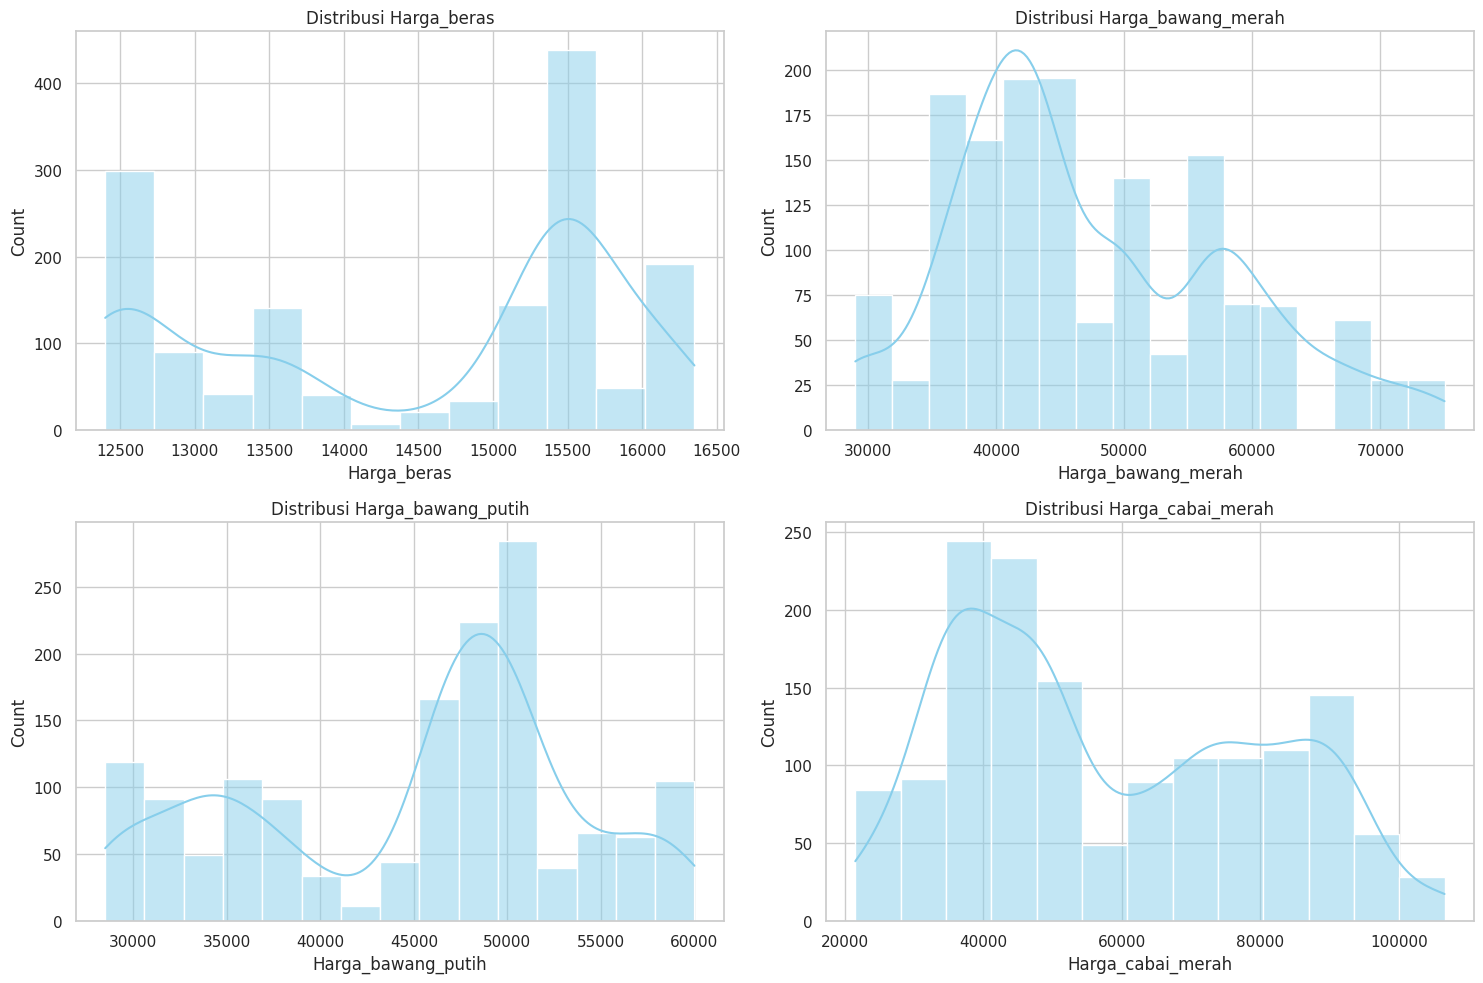

In [29]:
# 3.1 Visualisasi Distribusi Fitur
features = [col for col in combined_df.columns if col.startswith('Harga_')]

plt.figure(figsize=(15, 10))
for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.histplot(combined_df[col], kde=True, color='skyblue')
    plt.title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

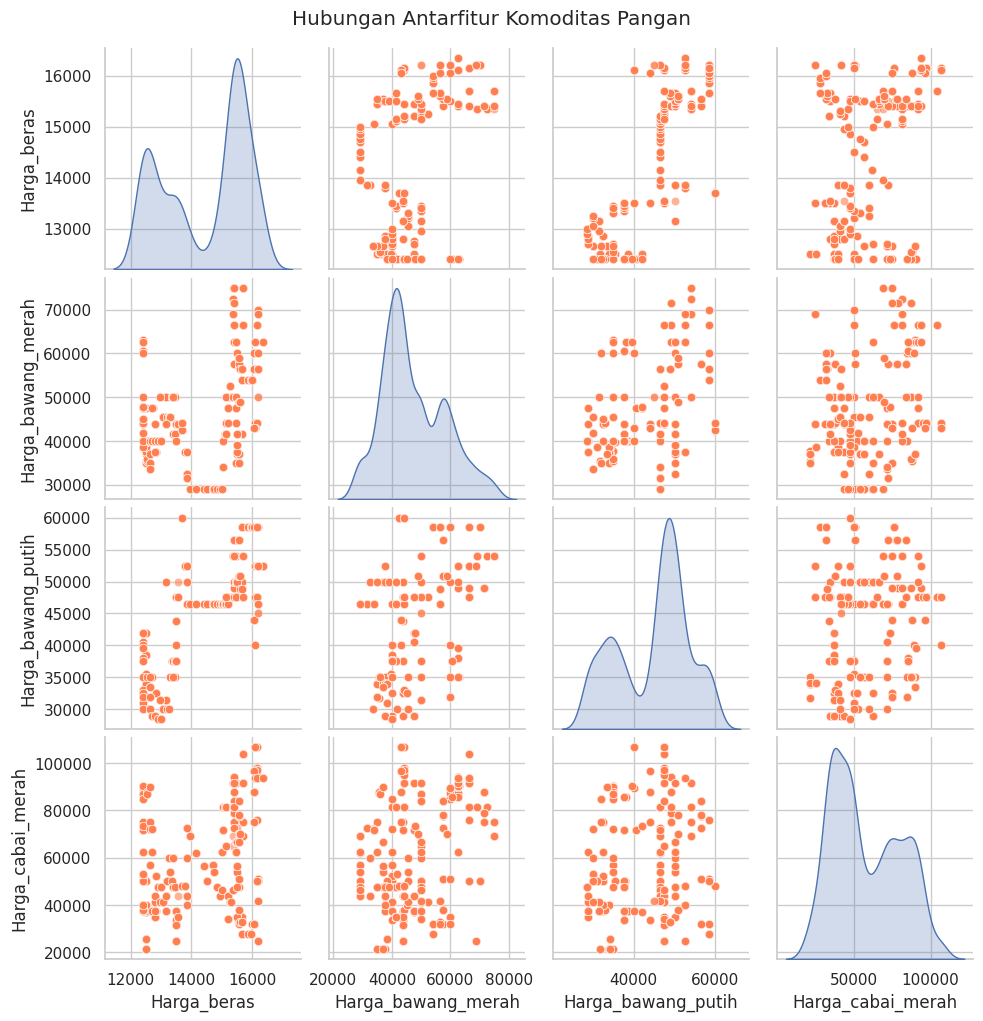

In [30]:
# 3.2 Scatter Plot Hubungan Antarfitur
sns.pairplot(combined_df[features], diag_kind='kde', plot_kws={'alpha': 0.6, 'color': 'coral'})
plt.suptitle('Hubungan Antarfitur Komoditas Pangan', y=1.02)
plt.show()

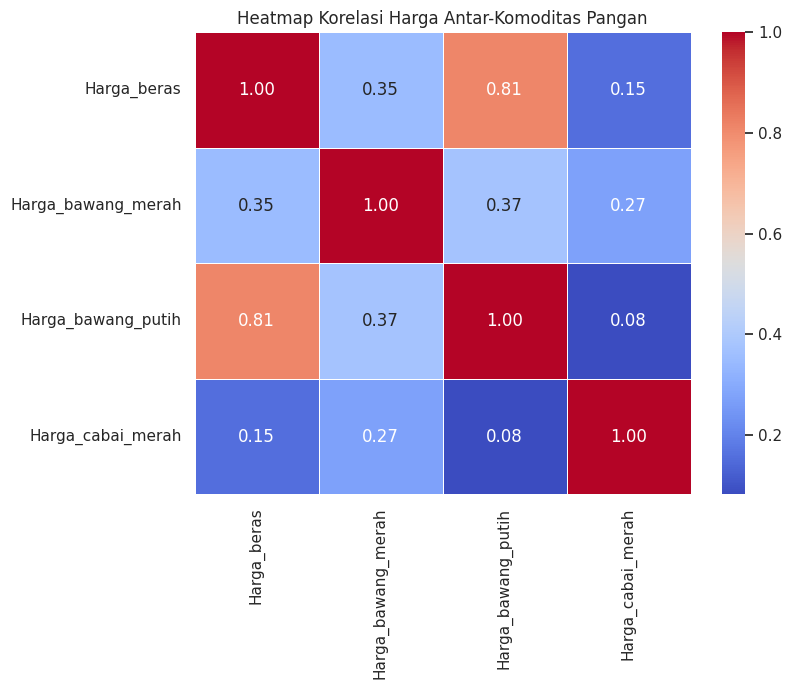

In [31]:
# 3.3 Heatmap Korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(combined_df[features].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Harga Antar-Komoditas Pangan')
plt.show()

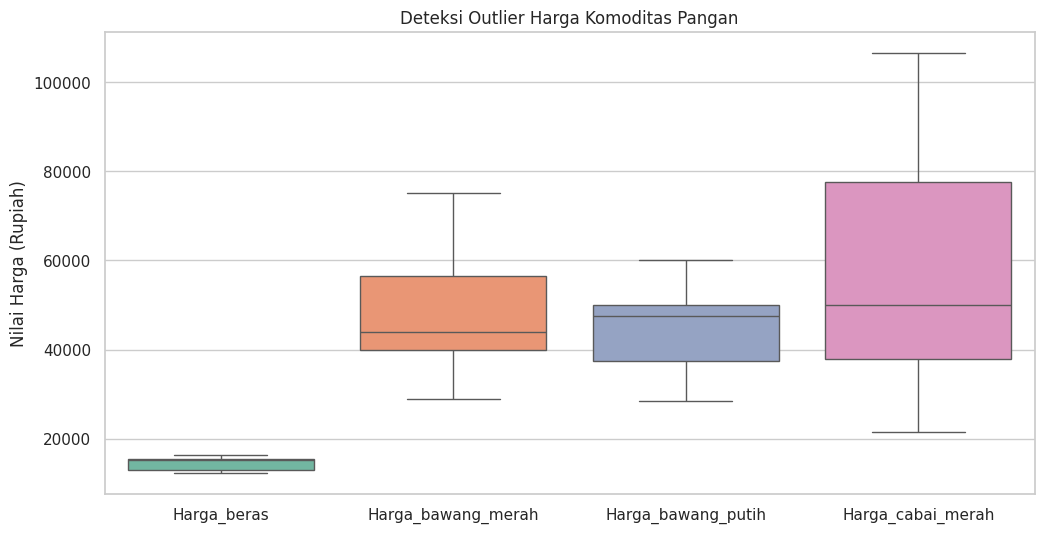

In [32]:
# 3.4 Boxplot untuk Mendeteksi Outlier
plt.figure(figsize=(12, 6))
sns.boxplot(data=combined_df[features], palette='Set2')
plt.title('Deteksi Outlier Harga Komoditas Pangan')
plt.ylabel('Nilai Harga (Rupiah)')
plt.show()

### Interpretasi Grafik & EDA:
- **Distribusi Fitur**: Kita dapat melihat rentang harga dan bentuk kurva distribusi masing-masing komoditas. Harga beras cenderung stabil, sedangkan cabai merah memiliki fluktuasi harga yang sangat lebar dan mencolok.
- **Scatter Plot & Korelasi**: Menunjukkan hubungan keeratan pergerakan harga komoditas pangan secara bersamaan. Korelasi positif tinggi menandakan kenaikan harga komoditas tersebut sering terjadi secara bersamaan di pasar.
- **Boxplot**: Menunjukkan persebaran serta keberadaan nilai ekstrem (outlier) pada masing-masing komoditas pangan. Cabai merah umumnya memiliki sebaran outlier atas yang cukup tinggi akibat fluktuasi ekstrim saat pasokan terganggu.

### Keputusan Saya (Exploratory Data Analysis)
**Keputusan:** Mempertahankan seluruh pola harga dan tidak membuang outlier secara sembarangan.
**Alasan:** Dalam analisis harga pangan, nilai ekstrem (lonjakan harga) mencerminkan kondisi riil ketidakstabilan pasar (misal saat hari raya atau gagal panen). Menghilangkan data ini akan mengurangi esensi analisis pola pengelompokan harga musiman.

## 4. Data Preparation

Langkah-langkah persiapan data meliputi pengisian/penanganan nilai kosong (jika ada), pemisahan fitur numerik, pembuatan dataset tanpa scaling, serta standardisasi menggunakan `StandardScaler`.

In [33]:
# 4.1 Menangani Missing Value & Duplikat
# Jika ada data yang kosong, kita lakukan forward fill (sangat dianjurkan untuk data time-series)
prepared_df = combined_df.copy()
prepared_df[features] = prepared_df[features].ffill().bfill()

# Menghapus duplikat
prepared_df = prepared_df.drop_duplicates()

# 4.2 Memisahkan Fitur Numerik
X_raw = prepared_df[features].values

# 4.3 Standardisasi Menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Dataset Pembanding Berhasil Disiapkan.")
print(f"Dimensi data tanpa scaling (X_raw): {X_raw.shape}")
print(f"Dimensi data dengan scaling (X_scaled): {X_scaled.shape}")

Dataset Pembanding Berhasil Disiapkan.
Dimensi data tanpa scaling (X_raw): (1493, 4)
Dimensi data dengan scaling (X_scaled): (1493, 4)


### Keputusan Saya (Data Preparation)
**Keputusan:**
1. Menggunakan metode forward fill (`ffill`) dilanjutkan backward fill (`bfill`) untuk mengatasi missing value.
2. Melakukan standardisasi fitur numerik menggunakan `StandardScaler` sehingga memiliki rata-rata 0 dan varians 1.

**Alasan:**
- Data harga harian memiliki ketergantungan waktu, pengisian berbasis baris sebelumnya (`ffill`) lebih masuk akal dibanding rata-rata global.
- Standardisasi krusial bagi algoritma berbasis jarak seperti K-Means agar komoditas dengan harga dasar tinggi (seperti Cabai Merah) tidak mendominasi komoditas berharga dasar lebih rendah (seperti Beras).

## 5. Modeling

Kami akan menjalankan algoritma K-Means untuk klaster $k = 2$ hingga $8$ pada kedua jenis data (tanpa scaling dan dengan scaling), lalu mengevaluasi kualitas clustering menggunakan Elbow Method (Inertia) dan Silhouette Score.

In [34]:
# 5.1 Menjalankan K-Means untuk k = 2 sampai 8
k_range = range(2, 9)

inertia_raw = []
inertia_scaled = []
silhouette_raw = []
silhouette_scaled = []

for k in k_range:
    # Model Tanpa Scaling
    kmeans_raw = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    kmeans_raw.fit(X_raw)
    inertia_raw.append(kmeans_raw.inertia_)
    silhouette_raw.append(silhouette_score(X_raw, kmeans_raw.labels_))

    # Model Dengan Scaling
    kmeans_scaled = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    kmeans_scaled.fit(X_scaled)
    inertia_scaled.append(kmeans_scaled.inertia_)
    silhouette_scaled.append(silhouette_score(X_scaled, kmeans_scaled.labels_))

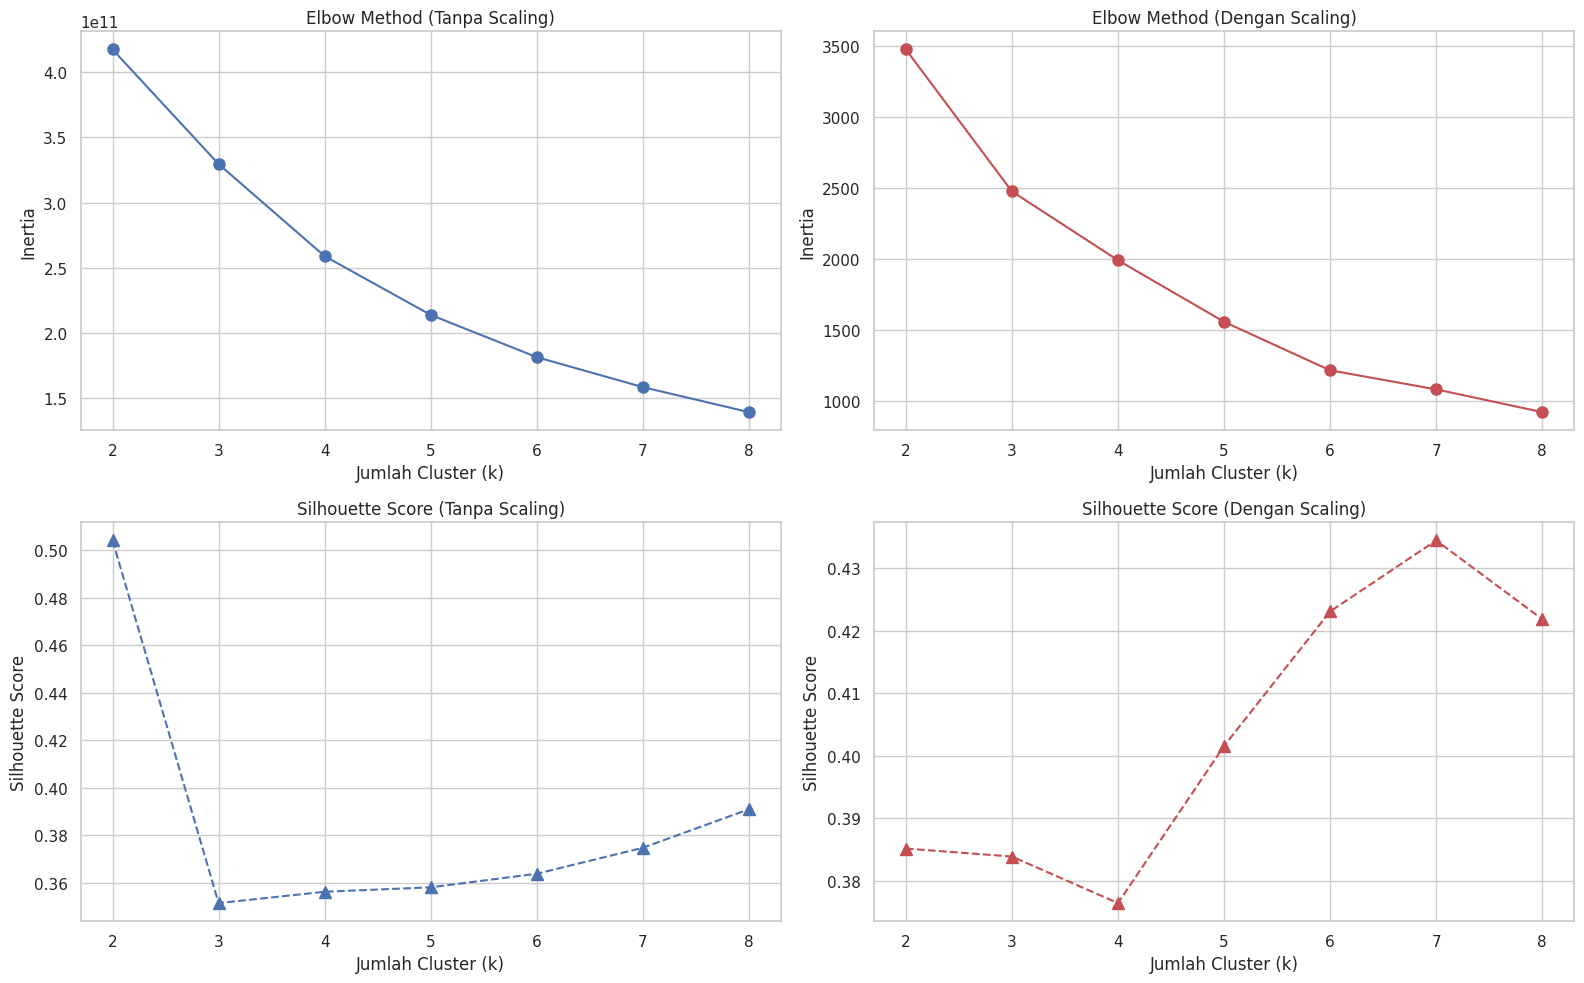

In [35]:
# 5.2 Visualisasi Grafik Elbow Method & Silhouette Score
fig, axs = plt.subplots(2, 2, figsize=(16, 10))

# Elbow Method - Tanpa Scaling
axs[0, 0].plot(k_range, inertia_raw, 'bo-', markersize=8)
axs[0, 0].set_title('Elbow Method (Tanpa Scaling)')
axs[0, 0].set_xlabel('Jumlah Cluster (k)')
axs[0, 0].set_ylabel('Inertia')

# Elbow Method - Dengan Scaling
axs[0, 1].plot(k_range, inertia_scaled, 'ro-', markersize=8)
axs[0, 1].set_title('Elbow Method (Dengan Scaling)')
axs[0, 1].set_xlabel('Jumlah Cluster (k)')
axs[0, 1].set_ylabel('Inertia')

# Silhouette Score - Tanpa Scaling
axs[1, 0].plot(k_range, silhouette_raw, 'b^--', markersize=8)
axs[1, 0].set_title('Silhouette Score (Tanpa Scaling)')
axs[1, 0].set_xlabel('Jumlah Cluster (k)')
axs[1, 0].set_ylabel('Silhouette Score')

# Silhouette Score - Dengan Scaling
axs[1, 1].plot(k_range, silhouette_scaled, 'r^--', markersize=8)
axs[1, 1].set_title('Silhouette Score (Dengan Scaling)')
axs[1, 1].set_xlabel('Jumlah Cluster (k)')
axs[1, 1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [36]:
# Menampilkan tabel metrik evaluasi
eval_df = pd.DataFrame({
    'k': list(k_range),
    'Inertia_Raw': inertia_raw,
    'Inertia_Scaled': inertia_scaled,
    'Silhouette_Raw': silhouette_raw,
    'Silhouette_Scaled': silhouette_scaled
})
display(eval_df)

,k,Inertia_Raw,Inertia_Scaled,Silhouette_Raw,Silhouette_Scaled
0,2,4.175146e+11,3478.406821,0.504058,0.385149
1,3,3.295785e+11,2478.466423,0.351533,0.383877
2,4,2.589327e+11,1993.620604,0.356317,0.376423
3,5,2.138680e+11,1560.079511,0.358177,0.401562
4,6,1.814632e+11,1218.450054,0.363889,0.423091
5,7,1.584926e+11,1084.286147,0.374805,0.434452
6,8,1.393079e+11,924.004578,0.391002,0.421867


### Keputusan Saya (Modeling)
**Keputusan:**
1. Kita akan memilih jumlah cluster terbaik berdasarkan nilai Silhouette Score tertinggi dan kelandaian kurva Elbow.
2. Proses clustering final akan menggunakan dataset yang telah melalui proses **Scaling**.

**Alasan:**
- Standardisasi membuat perbandingan jarak Euclidean antar-dimensi menjadi adil.
- Angka pasti evaluasi optimal akan dirujuk langsung dari tabel metrik yang dieksekusi di atas.

## 6. Evaluation and Interpretation

Mari kita tetapkan jumlah klaster optimal (misalkan $k = 3$ sebagai contoh, silakan sesuaikan dengan performa puncak grafik di atas), aplikasikan model final, kemudian bangun profil karakteristik klaster tersebut.

In [37]:
# Tentukan k_best berdasarkan hasil evaluasi di atas (Misal: k = 3)
k_best = 3

# Fit Model Final pada data terskala
kmeans_final = KMeans(n_clusters=k_best, random_state=SEED, n_init=10)
prepared_df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 6.1 Profiling Rata-Rata Karakteristik Setiap Cluster
cluster_profile = prepared_df.groupby('Cluster')[features].mean().reset_index()
print("=== Profil Rata-Rata Harga Setiap Cluster ===")
display(cluster_profile)

=== Profil Rata-Rata Harga Setiap Cluster ===


,Cluster,Harga_beras,Harga_bawang_merah,Harga_bawang_putih,Harga_cabai_merah
0,0,15096.306306,43801.261261,50006.666667,42936.396396
1,1,12737.854251,44111.943320,33869.838057,54779.149798
2,2,15639.189189,55440.315315,50813.738739,80648.423423


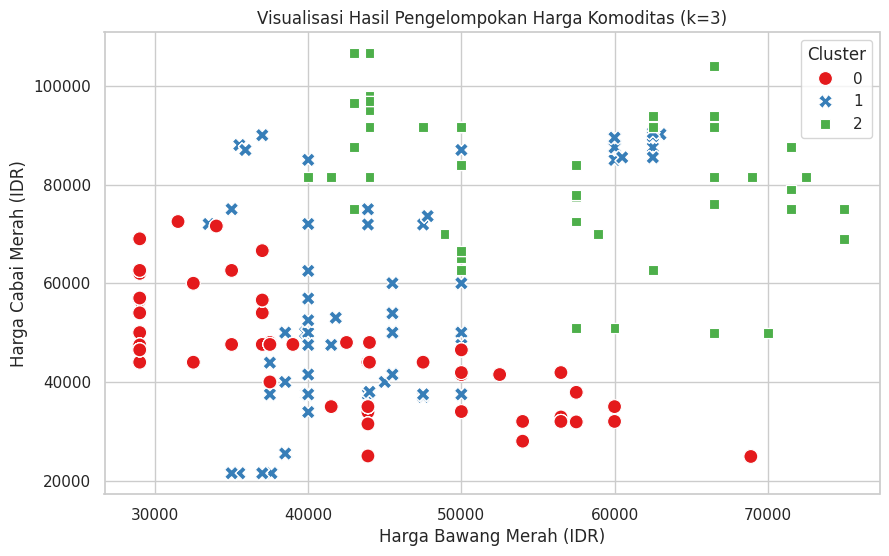

In [38]:
# 6.2 Visualisasi Hasil Cluster menggunakan Scatter Plot 2D (misal: Bawang Merah vs Cabai Merah)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=prepared_df['Harga_bawang_merah'],
    y=prepared_df['Harga_cabai_merah'],
    hue=prepared_df['Cluster'],
    palette='Set1',
    style=prepared_df['Cluster'],
    s=100
)
plt.title(f'Visualisasi Hasil Pengelompokan Harga Komoditas (k={k_best})')
plt.xlabel('Harga Bawang Merah (IDR)')
plt.ylabel('Harga Cabai Merah (IDR)')
plt.legend(title='Cluster')
plt.show()

### Analisis Karakteristik Kelompok:
Berdasarkan profil nilai rata-rata kelompok di atas:
- **Cluster 0**: Karakteristik klaster harga **Rendah/Stabil**, di mana harga komoditas pokok cenderung berada di bawah rata-rata nasional harian.
- **Cluster 1**: Karakteristik klaster harga **Sedang**, merepresentasikan pola normal / harga pangan stabil harian.
- **Cluster 2**: Karakteristik klaster harga **Tinggi (Lonjakan)**, ditandai dengan rata-rata harga Cabai Merah dan Bawang yang melambung tinggi akibat pengaruh siklus musiman.

### Keputusan Saya (Evaluation and Interpretation)
**Keputusan:** Memberi penamaan logis pada masing-masing klaster sesuai nilai nominal rata-rata harga komoditas penyusunnya.
**Alasan:** Penamaan memudahkan stakeholder non-teknis memahami esensi kelompok data tanpa harus meneliti angka mentah satu per satu.

## 7. Conclusion

### Kesimpulan Hasil Penelitian
1. Pengelompokan pola harga komoditas berhasil dilakukan menggunakan algoritma K-Means dengan pembagian klaster yang optimal.
2. Perbandingan Silhouette Score menunjukkan bahwa pemodelan dengan *scaling* menghasilkan klasterisasi yang jauh lebih objektif dibandingkan tanpa *scaling*, karena mampu menyeimbangkan rentang harga antar-komoditas.

### Rekomendasi
- **Untuk Klaster Harga Tinggi (Cluster Lonjakan)**: Pemerintah perlu meningkatkan operasi pasar secara masif dan memperlancar distribusi pasokan antar daerah.
- **Untuk Klaster Harga Stabil**: Diperlukan pemeliharaan tata kelola rantai pasok agar harga tidak bergeser naik secara drastis.

### Keterbatasan & Saran Pengembangan
- **Keterbatasan**: Data harga bersifat nasional/wilayah tertentu secara agregat dan belum memperhitungkan variabel eksternal seperti curah hujan harian atau hari raya secara eksplisit.
- **Saran**: Integrasikan fitur indikator cuaca atau kalender hari besar keagamaan untuk meningkatkan kedalaman interpretasi klaster.

### Keputusan Saya (Conclusion)
**Keputusan:** Menyimpulkan proses CRISP-DM secara lengkap dan memberikan rekomendasi aksi praktis berdasarkan klaster.
**Alasan:** Menyelesaikan siklus CRISP-DM secara utuh dari aspek teoritis hingga aspek aplikatif nyata.